In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Sequential
from sklearn.model_selection import train_test_split

SEED = 42        # seed 42, chosen by all students
NOISE = 0.15     # 15% Gaussian noise (assumption), test set only
LR = 0.01        # learning rate from the slide
BATCH = 128      # batch size from the teacher's example

keras.utils.set_random_seed(SEED)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Load all 70,000 MNIST images
(x_a, y_a), (x_b, y_b) = keras.datasets.mnist.load_data()
X_all = np.concatenate([x_a, x_b]).astype("float32") / 255.0
X_all = X_all[..., None]                      # shape: (70000, 28, 28, 1)
y_all = np.concatenate([y_a, y_b])
print("Total images:", X_all.shape[0])

def get_data(n):
    """Pick n images, split 70% train / 20% test / 10% validation (stratified)."""
    X, _, y, _ = train_test_split(X_all, y_all, train_size=n, stratify=y_all, random_state=SEED)
    X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, train_size=0.70, stratify=y, random_state=SEED)
    X_te, X_va, y_te, y_va = train_test_split(X_tmp, y_tmp, train_size=2/3, stratify=y_tmp, random_state=SEED)
    rng = np.random.default_rng(SEED)
    X_te_noisy = np.clip(X_te + NOISE * rng.standard_normal(X_te.shape), 0, 1).astype("float32")
    return (X_tr, y_tr), (X_va, y_va), (X_te, y_te), X_te_noisy

for n in [2500, 5000]:
    tr, va, te, _ = get_data(n)
    print(f"Size {n}: train={len(tr[1])}, test={len(te[1])}, validate={len(va[1])}")

GPU: []
Total images: 70000
Size 2500: train=1750, test=500, validate=250
Size 5000: train=3500, test=1000, validate=500


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)              │ (None, 14, 14, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 7, 7, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

=== Running size=2500, epochs=50 ===
=== Running size=2500, epochs=100 ===
=== Running size=5000, epochs=50 ===
=== Running size=5000, epochs=100 ===
Total rows saved: 300
 size  epochs  train_loss  val_loss  mse_noisy  mse_recon  improvement_%
 2500       1     0.40541   0.16730    0.01207    0.00526       56.47184
 2500       2     0.13485   0.10579    0.01207    0.00526       56.47184
 2500       3     0.09475   0.08727    0.01207    0.00526       56.47184
 2500       4     0.08155   0.07728    0.01207    0.00526       56.47184
 2500       5     0.07412   0.07245    0.01207    0.00526       56.47184
 2500       6     0.07061   0.07031    0.01207    0.00526       56.47184
 2500       7     0.06886   0.06843    0.01207    0.00526       56.47184
 2500       8     0.06743   0.06748    0.01207    0.00526       56.47184
 2500       9     0.06678   0.06702    0.01207    0.00526       56.47184
 2500      10     0.06616   0.06647    0.01207    0.00526       56.47184


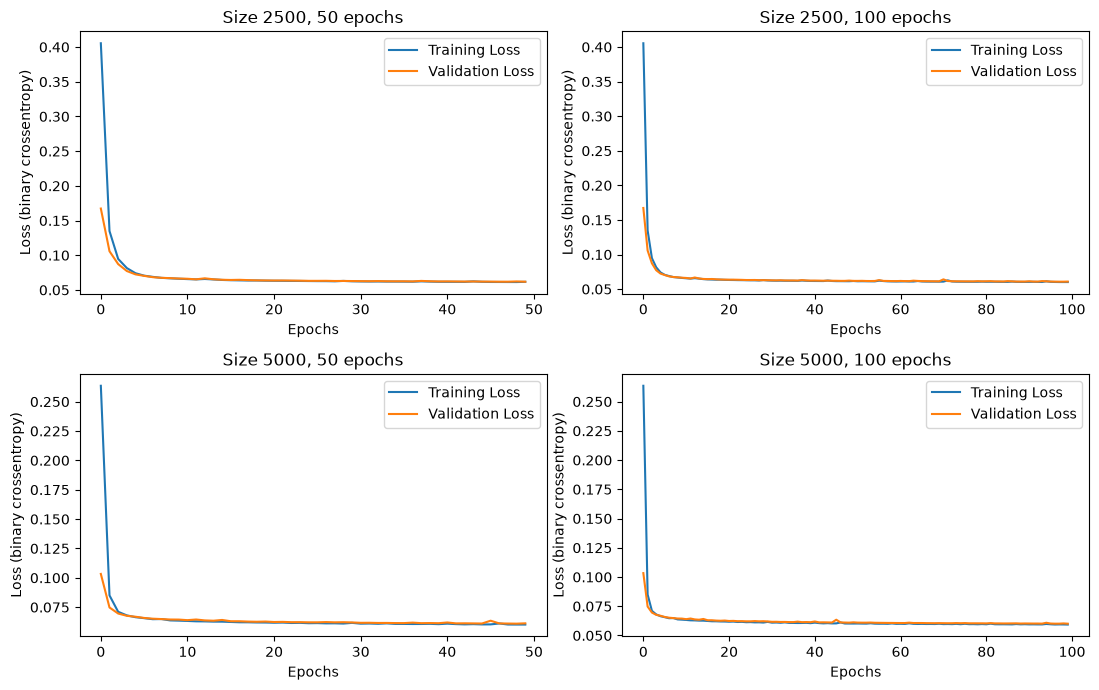

In [11]:
def build_stride_cnn():
    """Stride-Convolution CNN, copied from the teacher's file."""
    return Sequential([
        layers.Input(shape=(28, 28, 1)),
        # Encoder: downsampling with stride
        layers.Conv2D(32, 3, activation='relu', padding='same', strides=2),
        layers.Conv2D(64, 3, activation='relu', padding='same', strides=2),
        # Decoder: learned upsampling
        layers.Conv2DTranspose(64, 3, activation='relu', padding='same', strides=2),
        layers.Conv2DTranspose(32, 3, activation='relu', padding='same', strides=2),
        layers.Conv2D(1, 3, activation='sigmoid', padding='same')
    ])

build_stride_cnn().summary()

def mse(a, b):
    return float(np.mean((a - b) ** 2))

def run(n, epochs):
    keras.utils.set_random_seed(SEED)
    (X_tr, _), (X_va, _), (X_te, y_te), X_te_noisy = get_data(n)
    model = build_stride_cnn()
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR),
                  loss='binary_crossentropy', metrics=['mse'])
    
    # Train model
    hist = model.fit(X_tr, X_tr, epochs=epochs, batch_size=BATCH,
                     validation_data=(X_va, X_va), verbose=0)
    
    X_rec = model.predict(X_te_noisy, verbose=0)
    
    # Compute test metrics (can be shared across epochs for this run)
    m_noisy = mse(X_te_noisy, X_te)
    m_recon = mse(X_rec, X_te)
    imp_pct = (1 - m_recon / m_noisy) * 100
    
    # Collect row data for EVERY epoch
    epoch_rows = []
    for ep_idx in range(epochs):
        row = {
            "size": n,
            "epochs": ep_idx + 1,  # Epoch 1, 2, 3, ...
            "train_loss": hist.history["loss"][ep_idx],
            "val_loss": hist.history["val_loss"][ep_idx],
            "mse_noisy": m_noisy,
            "mse_recon": m_recon,
            "improvement_%": imp_pct
        }
        epoch_rows.append(row)
        
    art = dict(model=model, hist=hist.history, X_te=X_te, y_te=y_te,
               X_te_noisy=X_te_noisy, X_rec=X_rec)
    return epoch_rows, art

# Execute runs for all combinations and save to results.csv
artifacts, rows = {}, []
for n in [2500, 5000]:
    for ep in [50, 100]:
        print(f"=== Running size={n}, epochs={ep} ===")
        run_rows, artifacts[(n, ep)] = run(n, ep)
        rows.extend(run_rows)  # Use extend to add all epochs rows

results = pd.DataFrame(rows)
results.to_csv("results.csv", index=False)
print(f"Total rows saved: {len(results)}")
print(results.head(10).round(5).to_string(index=False))

# Training vs Validation loss, one plot per run
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, ((n, ep), a) in zip(axes.flat, artifacts.items()):
    ax.plot(a["hist"]["loss"], label="Training Loss")
    ax.plot(a["hist"]["val_loss"], label="Validation Loss")
    ax.set_title(f"Size {n}, {ep} epochs")
    ax.set_xlabel("Epochs")
    ax.set_ylabel("Loss (binary crossentropy)")
    ax.legend()
plt.tight_layout()
plt.savefig("loss_curves.png")
plt.show()

Best run (size, epochs): (2500, 50)


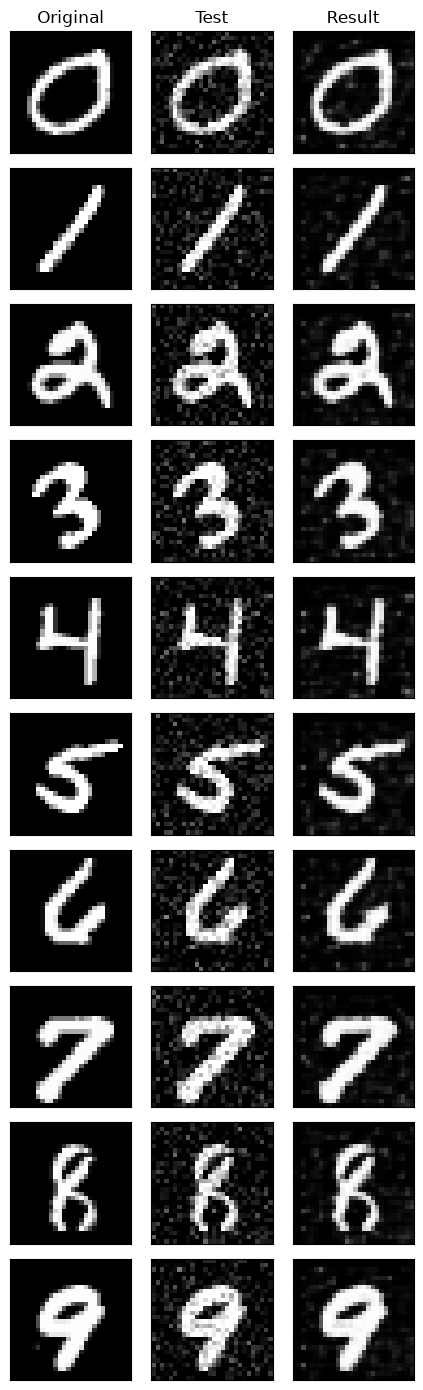

In [12]:
# Use the run with the lowest reconstruction error
best_key = min(artifacts, key=lambda k: mse(artifacts[k]["X_rec"], artifacts[k]["X_te"]))
print("Best run (size, epochs):", best_key)
a = artifacts[best_key]

idx = [int(np.where(a["y_te"] == d)[0][0]) for d in range(10)]   # first test image of each digit
fig, axes = plt.subplots(10, 3, figsize=(4.5, 14))
for r, i in enumerate(idx):
    for c, img in enumerate([a["X_te"][i], a["X_te_noisy"][i], a["X_rec"][i]]):
        axes[r, c].imshow(img[:, :, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
for ax, t in zip(axes[0], ["Original", "Test", "Result"]):
    ax.set_title(t)
plt.tight_layout()
plt.savefig("result_10_digits.png")
plt.show()

Size 2500, 50 epochs -> clean: 0.9620 | noisy: 0.9540 | denoised: 0.9540
Size 2500, 100 epochs -> clean: 0.9620 | noisy: 0.9540 | denoised: 0.9560
Size 5000, 50 epochs -> clean: 0.9650 | noisy: 0.9460 | denoised: 0.9510
Size 5000, 100 epochs -> clean: 0.9650 | noisy: 0.9460 | denoised: 0.9430


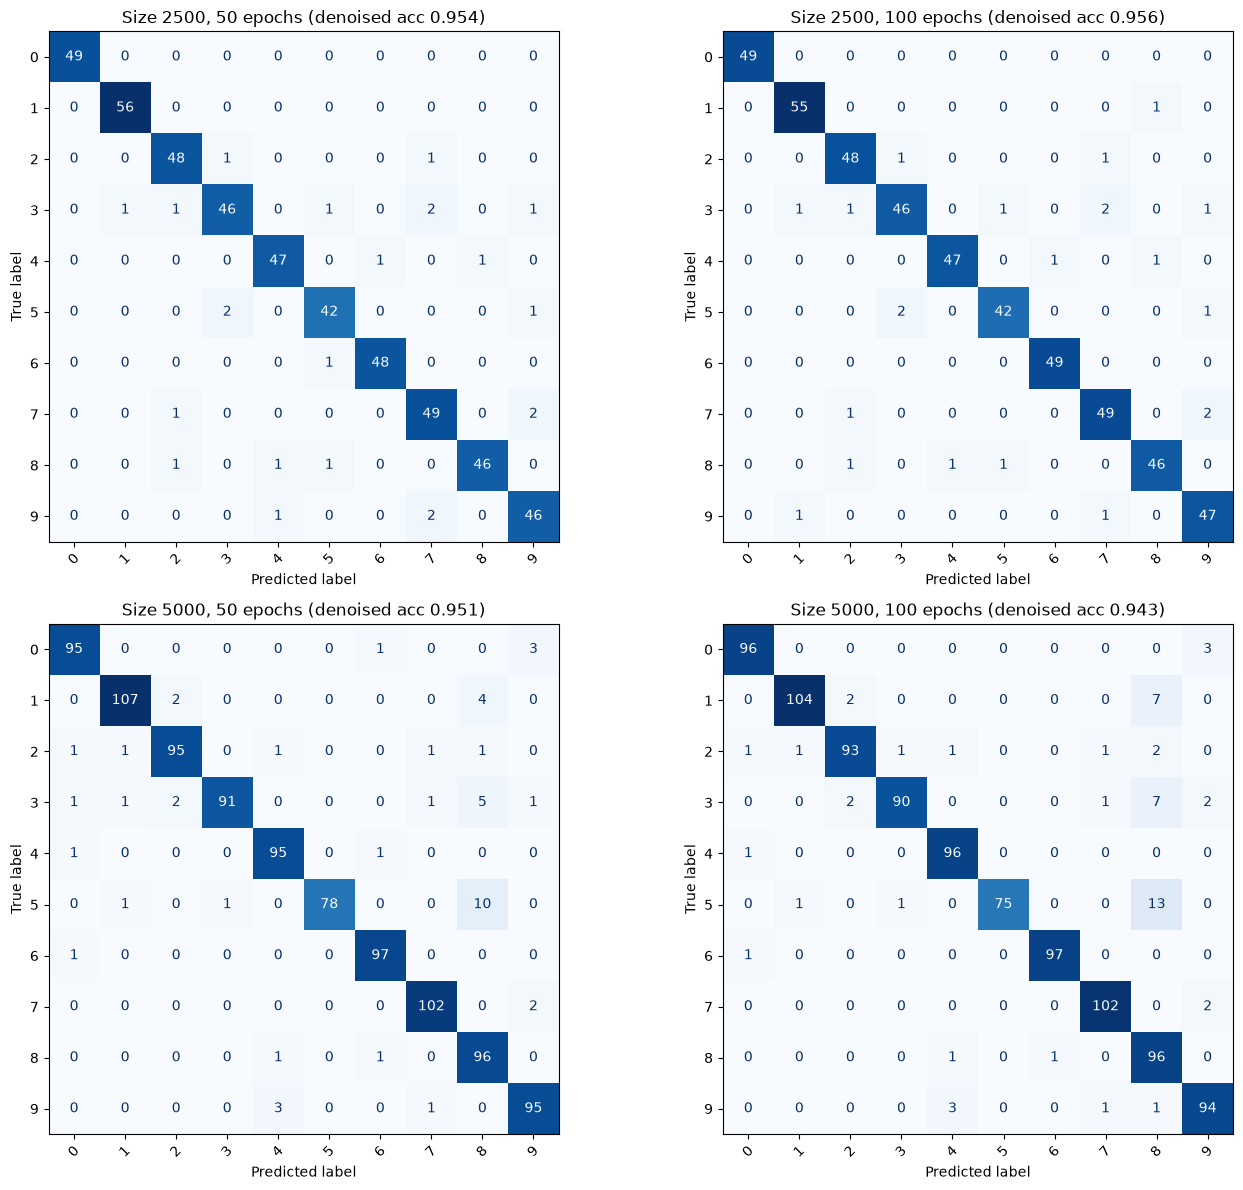

 size  epochs  acc_clean  acc_noisy  acc_denoised
 2500      50      0.962      0.954         0.954
 2500     100      0.962      0.954         0.956
 5000      50      0.965      0.946         0.951
 5000     100      0.965      0.946         0.943


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Assumption: an autoencoder has no class output, so we train a small classifier
# on CLEAN training images, then ask it to classify the denoised test images.
# One classifier per dataset size, shared by the 50 and 100 epoch runs,
# so the only thing that changes between matrices is the autoencoder.

def train_classifier(n):
    (X_tr, y_tr), (X_va, y_va), _, _ = get_data(n)
    keras.utils.set_random_seed(SEED)
    clf = Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(6, 5, activation='relu', padding='same'),
        layers.MaxPooling2D(2),
        layers.Conv2D(16, 5, activation='relu'),
        layers.MaxPooling2D(2),
        layers.Flatten(),
        layers.Dense(120, activation='relu'),
        layers.Dense(84, activation='relu'),
        layers.Dense(10, activation='softmax')
    ])
    clf.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    clf.fit(X_tr, y_tr, epochs=20, batch_size=BATCH, validation_data=(X_va, y_va), verbose=0)
    return clf

classifiers = {n: train_classifier(n) for n in [2500, 5000]}

def plot_cm(ax, cm, title):
    ConfusionMatrixDisplay(cm, display_labels=list(range(10))).plot(
        cmap="Blues", xticks_rotation=45, ax=ax, colorbar=False)
    ax.set_title(title)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
rows = []

for ax, ((n, ep), a) in zip(axes.flat, artifacts.items()):
    clf = classifiers[n]

    def accuracy(X):
        return float(np.mean(clf.predict(X, verbose=0).argmax(1) == a["y_te"]))

    acc_clean = accuracy(a["X_te"])
    acc_noisy = accuracy(a["X_te_noisy"])
    acc_denoised = accuracy(a["X_rec"])
    print(f"Size {n}, {ep} epochs -> clean: {acc_clean:.4f} | noisy: {acc_noisy:.4f} | denoised: {acc_denoised:.4f}")
    rows.append(dict(size=n, epochs=ep, acc_clean=acc_clean,
                     acc_noisy=acc_noisy, acc_denoised=acc_denoised))

    pred = clf.predict(a["X_rec"], verbose=0).argmax(1)
    cm = confusion_matrix(a["y_te"], pred, labels=list(range(10)))

    # subplot in the combined figure
    plot_cm(ax, cm, f"Size {n}, {ep} epochs (denoised acc {acc_denoised:.3f})")

    # separate image for each run (handy for slides)
    f2, ax2 = plt.subplots(figsize=(7, 6))
    plot_cm(ax2, cm, f"Confusion matrix: size {n}, {ep} epochs")
    f2.tight_layout()
    f2.savefig(f"confusion_{n}_{ep}.png")
    plt.close(f2)

fig.tight_layout()
fig.savefig("four_confusion_matrices.png")
plt.show()

acc_table = pd.DataFrame(rows)
acc_table.to_csv("classifier_accuracy.csv", index=False)
print(acc_table.round(4).to_string(index=False))